# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
  Representa una flor
- Número de instancias y características.
  150 y 4 caracteristicas
- Nombre y significado de cada característica.
  Longitud del sépalo, ancho del sépalo, longitud del pétalo y ancho del pétalo. Todas se miden en centímetros.
- Clases y cantidad de ejemplos por clase.
  Setosa, versicolor y virginica; hay 50 ejemplos de cada clase.
- Dimensiones de la matriz de características y del vector de etiquetas.
  50 flores por 4 medidas

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


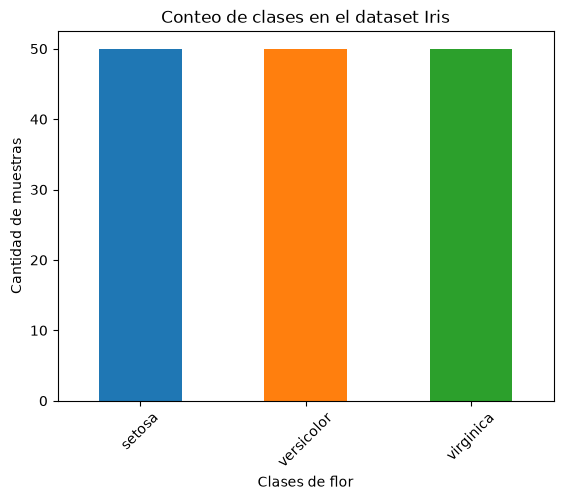

In [35]:
# Aquí cumple con el primer paso
import pandas as pd
from pandas import Series, DataFrame
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

#Carga el dataset
iris = load_iris()
#Matriz de caracteristicas 
iris_df = DataFrame(data=iris.data, columns=iris.feature_names)

display(iris_df.head())
# Vector de etiquetas: un número por flor.
y = pd.Series(iris.target, name="codigo_clase")



nombres_clase = dict(enumerate(iris.target_names))

iris2_df = iris_df.copy()

iris2_df["clase"] = y.map(nombres_clase)

conteos = iris2_df["clase"].value_counts()

conteos.plot(kind='bar', rot=45,color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title("Conteo de clases en el dataset Iris")
plt.xlabel("Clases de flor")
plt.ylabel("Cantidad de muestras")
plt.show()








# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

Espero que la regresión logística, el SVM lineal y el MLP sean sensibles a la escala de las características

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Regresión logística y el SVM lineal, porque sus limites son lineales.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
   
Porque debemos evaluarlos, validarlos, probarlos, compararlos.8

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.


In [4]:
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

iris = load_iris(as_frame=True)

X_iris = iris.data
Y_iris = iris.target


#60 20 20
X_ent_val, X_test, Y_ent_val, Y_test = train_test_split(X_iris, Y_iris, test_size=0.2, random_state=42, stratify=Y_iris)

X_ent, X_val, Y_ent, Y_val = train_test_split(X_ent_val, Y_ent_val, test_size=0.25, random_state=42, stratify=Y_ent_val)

def crear_clasificador(nombre, parametros):
    if nombre == "Gaussian Naive Bayes":
        return make_pipeline(StandardScaler(), GaussianNB(**parametros))
    elif nombre == "Regresión logística":
        return make_pipeline(StandardScaler(), LogisticRegression(**parametros))
    elif nombre == "SVM lineal":
        return make_pipeline(StandardScaler(), SVC(**parametros))
    elif nombre == "Árbol de decisión":
        return make_pipeline(StandardScaler(), DecisionTreeClassifier(**parametros))
    elif nombre == "Random Forest":
        return make_pipeline(StandardScaler(), RandomForestClassifier(**parametros))
    elif nombre == "Gradient Boosting":
        return make_pipeline(StandardScaler(), GradientBoostingClassifier(**parametros))
    elif nombre == "MLP":
        return make_pipeline(StandardScaler(), MLPClassifier(**parametros))
    else:
        raise ValueError(f"Nombre de clasificador desconocido: {nombre}")


def texto_parametros(parametros):
    return ', '.join(f"{k}={v}" for k, v in parametros.items())

# 1. Configuraciones iniciales.
configuraciones_iniciales_iris = {
    "Gaussian Naive Bayes": {
        "var_smoothing": 1e-9
    },
    "Regresión logística": {
        "C": 1,
        "max_iter": 3000,
        "random_state": 42
    },
    "SVM lineal": {
        "kernel": "linear",
        "C": 1
    },
    "Árbol de decisión": {
        "max_depth": None,
        "random_state": 42
    },
    "Random Forest": {
        "n_estimators": 100,
        "max_depth": None,
        "random_state": 42
    },
    "Gradient Boosting": {
        "n_estimators": 100,
        "learning_rate": 0.1,
        "random_state": 42
    },
    "MLP": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.0001,
        "max_iter": 3000,
        "random_state": 42
    }
}




2. Entrena con la partición de entrenamiento.


In [5]:
def entrenar_y_evaluar_modelos(X_ent, Y_ent, X_val, Y_val, configuraciones):
    resultados = []
    for nombre_clasificador, parametros in configuraciones.items():
        modelo = crear_clasificador(nombre_clasificador, parametros)
        modelo.fit(X_ent, Y_ent)
        prediccion = modelo.predict(X_val)
        accuracy = accuracy_score(Y_val, prediccion)
        f1_macro = f1_score(Y_val, prediccion, average='macro')
        resultados.append((nombre_clasificador, parametros, accuracy, f1_macro))

    return pd.DataFrame(resultados, columns=["Modelo", "Parámetros", "Accuracy", "F1 Macro"])

tabla_inicial = entrenar_y_evaluar_modelos(X_ent, Y_ent, X_val, Y_val, configuraciones_iniciales_iris)





3. Compara accuracy y F1 macro en validación.


In [6]:
display(tabla_inicial)

,Modelo,Parámetros,Accuracy,F1 Macro
0,Gaussian Naive Bayes,{'var_smoothing': 1e-09},0.933333,0.933333
1,Regresión logística,"{'C': 1, 'max_iter': 3000, 'random_state': 42}",0.933333,0.933333
2,SVM lineal,"{'kernel': 'linear', 'C': 1}",0.933333,0.933333
3,Árbol de decisión,"{'max_depth': None, 'random_state': 42}",0.933333,0.933333
4,Random Forest,"{'n_estimators': 100, 'max_depth': None, 'rand...",0.933333,0.933333
5,Gradient Boosting,"{'n_estimators': 100, 'learning_rate': 0.1, 'r...",0.900000,0.899749
6,MLP,"{'hidden_layer_sizes': (50,), 'alpha': 0.0001,...",0.933333,0.933333


4. Realiza ajustes limitados usando solamente validación.


In [7]:
#  Ajustes para comparar los modelos.
# Ajuste 1
ajustes_iris_1 = {
    "Gaussian Naive Bayes": {
        "var_smoothing": 1e-8
    },
    "Regresión logística": {
        "C": 0.1,
        "max_iter": 3000,
        "random_state": 42
    },
    "SVM lineal": {
        "kernel": "linear",
        "C": 0.1
    },
    "Árbol de decisión": {
        "max_depth": 2,
        "random_state": 42
    },
    "Random Forest": {
        "n_estimators": 200,
        "max_depth": None,
        "random_state": 42
    },
    "Gradient Boosting": {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "random_state": 42
    },
    "MLP": {
        "hidden_layer_sizes": (30,),
        "alpha": 0.0001,
        "max_iter": 3000,
        "random_state": 42
    }
}


# Ajuste 2
ajustes_iris_2 = {
    "Gaussian Naive Bayes": {
        "var_smoothing": 1e-7
    },
    "Regresión logística": {
        "C": 10,
        "max_iter": 3000,
        "random_state": 42
    },
    "SVM lineal": {
        "kernel": "linear",
        "C": 10
    },
    "Árbol de decisión": {
        "max_depth": 4,
        "random_state": 42
    },
    "Random Forest": {
        "n_estimators": 100,
        "max_depth": 4,
        "random_state": 42
    },
    "Gradient Boosting": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "random_state": 42
    },
    "MLP": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.01,
        "max_iter": 3000,
        "random_state": 42
    }
}



tabla_ajustes = entrenar_y_evaluar_modelos(X_ent, Y_ent, X_val, Y_val, ajustes_iris_1)
display(tabla_ajustes)
tabla_ajustes2 = entrenar_y_evaluar_modelos(X_ent, Y_ent, X_val, Y_val, ajustes_iris_2)
display(tabla_ajustes2)

,Modelo,Parámetros,Accuracy,F1 Macro
0,Gaussian Naive Bayes,{'var_smoothing': 1e-08},0.933333,0.933333
1,Regresión logística,"{'C': 0.1, 'max_iter': 3000, 'random_state': 42}",0.866667,0.865320
2,SVM lineal,"{'kernel': 'linear', 'C': 0.1}",0.933333,0.933333
3,Árbol de decisión,"{'max_depth': 2, 'random_state': 42}",0.900000,0.899749
4,Random Forest,"{'n_estimators': 200, 'max_depth': None, 'rand...",0.933333,0.933333
5,Gradient Boosting,"{'n_estimators': 100, 'learning_rate': 0.05, '...",0.900000,0.899749
6,MLP,"{'hidden_layer_sizes': (30,), 'alpha': 0.0001,...",0.933333,0.933333


,Modelo,Parámetros,Accuracy,F1 Macro
0,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.933333,0.933333
1,Regresión logística,"{'C': 10, 'max_iter': 3000, 'random_state': 42}",0.933333,0.933333
2,SVM lineal,"{'kernel': 'linear', 'C': 10}",0.900000,0.899749
3,Árbol de decisión,"{'max_depth': 4, 'random_state': 42}",0.933333,0.933333
4,Random Forest,"{'n_estimators': 100, 'max_depth': 4, 'random_...",0.933333,0.933333
5,Gradient Boosting,"{'n_estimators': 200, 'learning_rate': 0.05, '...",0.900000,0.899749
6,MLP,"{'hidden_layer_sizes': (50,), 'alpha': 0.01, '...",0.933333,0.933333


5. Congela las configuraciones.


In [8]:
#Nos quedaremos con las iniciales que fueron las que mas nos rindieron 
configuraciones_congeladas_iris = {
    "Gaussian Naive Bayes": {
        "var_smoothing": 1e-9
    },
    "Regresión logística": {
        "C": 1,
        "max_iter": 3000,
        "random_state": 42
    },
    "SVM lineal": {
        "kernel": "linear",
        "C": 1
    },
    "Árbol de decisión": {
        "max_depth": None,
        "random_state": 42
    },
    "Random Forest": {
        "n_estimators": 100,
        "max_depth": None,
        "random_state": 42
    },
    "Gradient Boosting": {
        "n_estimators": 100,
        "learning_rate": 0.1,
        "random_state": 42
    },
    "MLP": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.0001,
        "max_iter": 3000,
        "random_state": 42
    }
}


def texto_parametros(parametros):
    return ', '.join(f"{k}={v}" for k, v in parametros.items())



6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

,Modelo,Transformación,Hiperparámetros,Accuracy de prueba,F1 Macro de prueba
0,Gaussian Naive Bayes,StandardScaler,{'var_smoothing': 1e-09},0.966667,0.966583
1,Regresión logística,StandardScaler,"{'C': 1, 'max_iter': 3000, 'random_state': 42}",0.933333,0.933333
2,SVM lineal,StandardScaler,"{'kernel': 'linear', 'C': 1}",1.000000,1.000000
3,Árbol de decisión,StandardScaler,"{'max_depth': None, 'random_state': 42}",0.933333,0.933333
4,Random Forest,StandardScaler,"{'n_estimators': 100, 'max_depth': None, 'rand...",0.900000,0.899749
5,Gradient Boosting,StandardScaler,"{'n_estimators': 100, 'learning_rate': 0.1, 'r...",0.966667,0.966583
6,MLP,StandardScaler,"{'hidden_layer_sizes': (50,), 'alpha': 0.0001,...",0.966667,0.966583


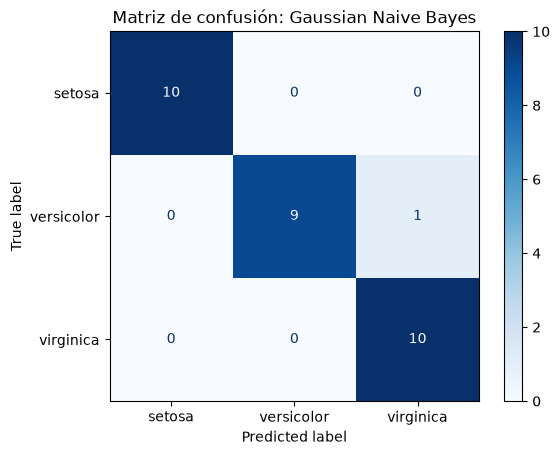

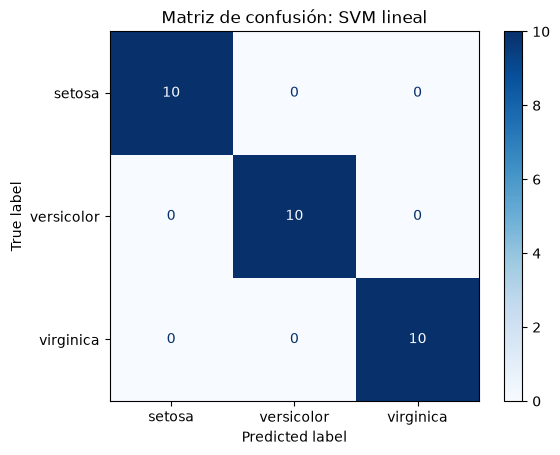

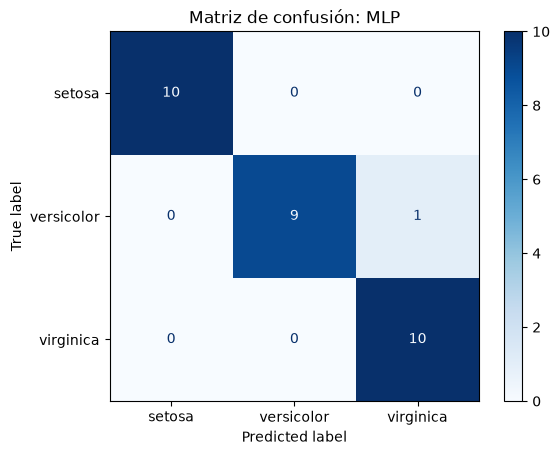

In [9]:
# 6. Reentrenar las configuraciones congeladas con entrenamiento + validación.
X_final_iris = pd.concat([X_ent, X_val])
Y_final_iris = pd.concat([Y_ent, Y_val])

prediccion_final = {}
modelos_finales_iris = {}

def entrenar_y_evaluar_modelos_final(X_final_iris, Y_final_iris, X_test, Y_test, configuraciones, prediccion_final):
    resultados = []
    for nombre_clasificador, parametros in configuraciones.items():
        modelo = crear_clasificador(nombre_clasificador, parametros)
        modelo.fit(X_final_iris, Y_final_iris)
        prediccion = modelo.predict(X_test)
        prediccion_final[nombre_clasificador] = prediccion
        accuracy = accuracy_score(Y_test, prediccion)
        f1_macro = f1_score(Y_test, prediccion, average='macro')
        modelos_finales_iris[nombre_clasificador] = modelo
        resultados.append((nombre_clasificador,"StandardScaler", parametros, accuracy, f1_macro))

    return pd.DataFrame(resultados, columns=["Modelo", "Transformación", "Hiperparámetros", "Accuracy de prueba" , "F1 Macro de prueba"])

tabla_final_iris = entrenar_y_evaluar_modelos_final(X_final_iris, Y_final_iris, X_test, Y_test, configuraciones_congeladas_iris, prediccion_final)
display(tabla_final_iris)

#Matriz de confusión para cada modelo
for nombre in ["Gaussian Naive Bayes", "SVM lineal", "MLP"]:
    ConfusionMatrixDisplay.from_predictions(Y_test, prediccion_final[nombre], display_labels=iris.target_names, cmap=plt.cm.Blues)
    plt.title(f"Matriz de confusión: {nombre}")
    plt.show()



## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
   
SVM lineal nos dio un 100%, pero mi criterio iria por Random Forest porque es el que mas puede generalizar los datos, en cambio, con SVM podriamos tener un sobreajuste.

2. ¿Cuál fue el modelo más sencillo de programar?

GNB solo tiene un parametro, no es como los otros que tuve que poner varios hiperparametros y probarlos.
3. ¿Accuracy y F1 macro cuentan la misma historia?

Accuracy y F1 macro pueden ser parecidos en Iris porque hay la misma cantidad de flores de cada clase, pero no miden exactamente lo mismo.

4. ¿Cuál es la diferencia entre las métricas macro y micro?

F1 macro calcula F1 por clase y luego promedia dando el mismo peso a cada clase. F1 micro reúne todos los aciertos y errores antes de calcular F1. En clasificación multiclase de una sola etiqueta, F1 micro coincide con accuracy.

5. ¿Qué aporta el MLP frente a un modelo lineal?

El MLP puede aprender fronteras no lineales y más complejas. Eso no garantiza que supere a un modelo lineal.

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

In [10]:
prediccion_svm = prediccion_final["SVM lineal"]

#Gpt,  la mascara compara prediccion con el test [0,1,2] [0,0,2] y nos da True en los indices donde hay error y False donde no hay error.
mascara_error = prediccion_svm != Y_test.to_numpy()
indices_error = X_test.index[mascara_error][:2] #Aqui se guardan los indices de errores pero solo tomamos los 2 primeros para mostrar.

if len(indices_error) == 0:
    print("El SVM lineal no cometió errores en prueba.")
else:
    errores_iris = X_test.loc[indices_error].copy() # tomas ciertas filas, en este caso las del error 

    pred_svm_serie = pd.Series( #Hacemos una serie de pandas para poder hacer un map y obtener el nombre de la clase en vez del numero
        prediccion_svm, 
        index=X_test.index
    )

    errores_iris["Clase real"] = Y_test.loc[indices_error].map(
        dict(enumerate(iris.target_names))
    )

    errores_iris["Clase predicha"] = pred_svm_serie.loc[
        indices_error
    ].map(dict(enumerate(iris.target_names))) # Hace map para darnos el nombre de la clase en vez del numero

    display(errores_iris)

El SVM lineal no cometió errores en prueba.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

El objetivo de Diabetes es una medida numérica de progresión de la enfermedad aproximadamente un año después de la medición inicial. Las variables son age, sex, bmi, bp y seis mediciones sanguíneas: s1, s2, s3, s4, s5 y s6. 

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

La descripción de scikit-learn indica que las características ya tienen transformaciones y escalamiento; sus valores no deben interpretarse directamente como unidades físicas originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No espero que un modelo más flexible siempre produzca menor error en datos nuevos. Puede aprender detalles particulares del entrenamiento y rendir peor frente a ejemplos nuevos.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.


In [23]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor


diabetes = load_diabetes(as_frame=True)

X_diabetes = diabetes.data
y_diabetes = diabetes.target

#print(diabetes.DESCR)

X_ent_val_d, X_test_d, Y_ent_val_d, Y_test_d = train_test_split(X_diabetes, y_diabetes, test_size=0.20, random_state=42)

X_ent_d, X_val_d, Y_ent_d, Y_val_d = train_test_split(X_ent_val_d, Y_ent_val_d, test_size=0.25, random_state=42)

def crear_regresor(nombre, parametros):
    if nombre == "Regresión lineal":
        return make_pipeline(StandardScaler(), LinearRegression(**parametros))
    elif nombre == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**parametros))
    elif nombre == "Lasso":
        return make_pipeline(StandardScaler(), Lasso(**parametros))
    elif nombre == "kNN de regresión":
        return make_pipeline(StandardScaler(), KNeighborsRegressor(**parametros))
    elif nombre == "Árbol de regresión":
        return make_pipeline(StandardScaler(), DecisionTreeRegressor(**parametros))
    elif nombre == "Random Forest de regresión":
        return make_pipeline(StandardScaler(), RandomForestRegressor(**parametros))
    elif nombre == "Gradient Boosting de regresión":
        return make_pipeline(StandardScaler(), GradientBoostingRegressor(**parametros))
    elif nombre == "MLP de regresión":
        red_neuronal = MLPRegressor(**parametros)
        # Escala X y también y solo durante fit.
        # predict devuelve el objetivo otra vez en su escala original.
        return TransformedTargetRegressor(
            regressor=make_pipeline(
                StandardScaler(),
                red_neuronal
            ),
            transformer=StandardScaler()
        )

    else:
        raise ValueError(f"Nombre de regresor desconocido: {nombre}")

    
def texto_parametros_d(parametros):
    return ', '.join(f"{k}={v}" for k, v in parametros.items())

def calcular_metricas(real, prediccion):
    mae = mean_absolute_error(real, prediccion)
    rmse = np.sqrt(mean_squared_error(real, prediccion))
    r2 = r2_score(real, prediccion)

    return mae, rmse, r2    



Configuracion inicial

In [24]:
configuraciones_iniciales_regresion = {
    "Regresión lineal": {},
    "Ridge": {
        "alpha": 1.0
    },
    "Lasso": {
        "alpha": 1.0,
        "max_iter": 20000
    },
    "kNN de regresión": {
        "n_neighbors": 5
    },
    "Árbol de regresión": {
        "random_state": 42
    },
    "Random Forest de regresión": {
        "n_estimators": 100,
        "random_state": 42
    },
    "Gradient Boosting de regresión": {
        "n_estimators": 100,
        "learning_rate": 0.1,
        "random_state": 42
    },
    "MLP de regresión": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.0001,
        "max_iter": 5000,
        "random_state": 42
    }
}


def entrenar_y_evaluar_modelos_regresion(X_ent, Y_ent, X_val, Y_val, configuraciones):
    resultados = []
    for nombre_clasificador, parametros in configuraciones.items():
        modelo = crear_regresor(nombre_clasificador, parametros)
        modelo.fit(X_ent, Y_ent)
        prediccion = modelo.predict(X_val)
        mae, rmse, r2 = calcular_metricas(Y_val, prediccion)
        resultados.append((nombre_clasificador, parametros, mae, rmse, r2))

    return pd.DataFrame(resultados, columns=["Modelo", "Parámetros", "MAE", "RMSE", "R²"])

tabla_inicial = entrenar_y_evaluar_modelos_regresion(X_ent_d, Y_ent_d, X_val_d, Y_val_d, configuraciones_iniciales_regresion)

display(tabla_inicial)


,Modelo,Parámetros,MAE,RMSE,R²
0,Regresión lineal,{},42.938900,51.193714,0.521650
1,Ridge,{'alpha': 1.0},42.723050,51.103145,0.523341
2,Lasso,"{'alpha': 1.0, 'max_iter': 20000}",42.470345,51.060247,0.524140
3,kNN de regresión,{'n_neighbors': 5},45.292135,56.833330,0.410452
4,Árbol de regresión,{'random_state': 42},50.550562,66.101131,0.202500
5,Random Forest de regresión,"{'n_estimators': 100, 'random_state': 42}",44.435843,54.152474,0.464759
6,Gradient Boosting de regresión,"{'n_estimators': 100, 'learning_rate': 0.1, 'r...",44.543078,53.758481,0.472519
7,MLP de regresión,"{'hidden_layer_sizes': (50,), 'alpha': 0.0001,...",56.133645,68.332446,0.147750


Ajustes para comparar los modelos de regresión.

In [25]:
ajustes_regresion_1 = {
    "Regresión lineal": {},
    "Ridge": {
        "alpha": 0.1
    },
    "Lasso": {
        "alpha": 0.1,
        "max_iter": 20000
    },
    "kNN de regresión": {
        "n_neighbors": 3
    },
    "Árbol de regresión": {
        "max_depth": 3,
        "random_state": 42
    },
    "Random Forest de regresión": {
        "n_estimators": 200,
        "max_depth": None,
        "random_state": 42
    },
    "Gradient Boosting de regresión": {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "random_state": 42
    },
    "MLP de regresión": {
        "hidden_layer_sizes": (30,),
        "alpha": 0.0001,
        "max_iter": 5000,
        "random_state": 42
    }
}


ajustes_regresion_2 = {
    "Regresión lineal": {},

    "Ridge": {
        "alpha": 1.0
    },

    "Lasso": {
        "alpha": 0.01,
        "max_iter": 20000
    },

    "kNN de regresión": {
        "n_neighbors": 7,
        "weights": "distance",
        "p": 2
    },

    "Árbol de regresión": {
        "max_depth": 5,
        "min_samples_leaf": 5,
        "random_state": 42
    },

    "Random Forest de regresión": {
        "n_estimators": 300,
        "max_depth": 10,
        "min_samples_leaf": 2,
        "random_state": 42
    },

    "Gradient Boosting de regresión": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2,
        "random_state": 42
    },

    "MLP de regresión": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.001,
        "max_iter": 5000,
        "random_state": 42
    }
}

tabla_ajuste1 = entrenar_y_evaluar_modelos_regresion(X_ent_d, Y_ent_d, X_val_d, Y_val_d, ajustes_regresion_1)
tabla_ajuste2 = entrenar_y_evaluar_modelos_regresion(X_ent_d, Y_ent_d, X_val_d, Y_val_d, ajustes_regresion_2)

display(tabla_ajuste1)
display(tabla_ajuste2)

,Modelo,Parámetros,MAE,RMSE,R²
0,Regresión lineal,{},42.938900,51.193714,0.521650
1,Ridge,{'alpha': 0.1},42.906384,51.174071,0.522017
2,Lasso,"{'alpha': 0.1, 'max_iter': 20000}",42.642441,51.099703,0.523405
3,kNN de regresión,{'n_neighbors': 3},45.921348,61.602821,0.307350
4,Árbol de regresión,"{'max_depth': 3, 'random_state': 42}",46.569194,58.226727,0.381189
5,Random Forest de regresión,"{'n_estimators': 200, 'max_depth': None, 'rand...",44.384157,54.298580,0.461867
6,Gradient Boosting de regresión,"{'n_estimators': 100, 'learning_rate': 0.05, '...",45.457946,54.879342,0.450294
7,MLP de regresión,"{'hidden_layer_sizes': (30,), 'alpha': 0.0001,...",46.487999,59.763254,0.348099


,Modelo,Parámetros,MAE,RMSE,R²
0,Regresión lineal,{},42.938900,51.193714,0.521650
1,Ridge,{'alpha': 1.0},42.723050,51.103145,0.523341
2,Lasso,"{'alpha': 0.01, 'max_iter': 20000}",42.907269,51.177697,0.521949
3,kNN de regresión,"{'n_neighbors': 7, 'weights': 'distance', 'p': 2}",45.415908,56.816333,0.410805
4,Árbol de regresión,"{'max_depth': 5, 'min_samples_leaf': 5, 'rando...",50.885035,63.342571,0.267674
5,Random Forest de regresión,"{'n_estimators': 300, 'max_depth': 10, 'min_sa...",43.821876,53.596860,0.475686
6,Gradient Boosting de regresión,"{'n_estimators': 200, 'learning_rate': 0.05, '...",43.895146,53.710309,0.473464
7,MLP de regresión,"{'hidden_layer_sizes': (50,), 'alpha': 0.001, ...",56.011275,68.151683,0.152253


## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.


In [26]:


alpha = [0.01, 0.1, 1.0, 10.0, 100.0]
def regularizar_modelos_regresion(X_ent, Y_ent, X_val, Y_val, alpha_values):
    resultados = []
    for alpha in alpha_values:
        # Ridge
        ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        ridge_model.fit(X_ent, Y_ent)
        pred_ent_ridge = ridge_model.predict(X_ent)
        pred_val_ridge = ridge_model.predict(X_val)
        coeficientes_ridge = ridge_model.named_steps['ridge'].coef_
        resultados.append(["Ridge", alpha, np.linalg.norm(coeficientes_ridge), np.nan, mean_absolute_error(Y_ent, pred_ent_ridge), mean_absolute_error(Y_val, pred_val_ridge)])

        # Lasso
        lasso_model = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=20000))
        lasso_model.fit(X_ent, Y_ent)
        pred_ent_lasso = lasso_model.predict(X_ent)
        pred_val_lasso = lasso_model.predict(X_val)
        coeficientes_lasso = lasso_model.named_steps['lasso'].coef_
        cantidad_ceros = np.sum(np.isclose(coeficientes_lasso, 0))
        resultados.append(["Lasso", alpha, np.linalg.norm(coeficientes_lasso), cantidad_ceros, mean_absolute_error(Y_ent, pred_ent_lasso), mean_absolute_error(Y_val, pred_val_lasso)])


    return pd.DataFrame(resultados, columns=["Modelo", "Alpha", "Magnitud de coeficientes", "Coeficientes nulos en lasso", "MAE Entrenamiento", "MAE Validación"])    


tabla_regularizacion = regularizar_modelos_regresion(X_ent_d, Y_ent_d, X_val_d, Y_val_d, alpha)
display(tabla_regularizacion)



,Modelo,Alpha,Magnitud de coeficientes,Coeficientes nulos en lasso,MAE Entrenamiento,MAE Validación
0,Ridge,0.01,77.851480,NaN,43.793353,42.935269
1,Lasso,0.01,76.051760,0.0,43.794843,42.907269
2,Ridge,0.10,75.549068,NaN,43.791867,42.906384
3,Lasso,0.10,58.770809,0.0,43.820002,42.642441
4,Ridge,1.00,60.880338,NaN,43.790833,42.723050
5,Lasso,1.00,41.985541,1.0,44.115428,42.470345
6,Ridge,10.00,41.916915,NaN,43.936010,42.619698
7,Lasso,10.00,31.128626,6.0,48.253951,45.144958
8,Ridge,100.00,32.778169,NaN,45.085244,43.432324
9,Lasso,100.00,0.000000,10.0,66.677284,64.128788


Congelamiento y entrenamiento final de los modelos de regresión con los mejores hiperparámetros encontrados en la validación.

In [33]:
ajustes_congelados_diabetes = {
    "Regresión lineal": {},

    "Ridge": {
        "alpha": 1.0
    },

    "Lasso": {
        "alpha": 1.0,
        "max_iter": 20000
    },

    "kNN de regresión": {
        "n_neighbors": 7,
        "weights": "distance",
        "p": 2
    },

    "Árbol de regresión": {
        "max_depth": 5,
        "min_samples_leaf": 5,
        "random_state": 42
    },

    "Random Forest de regresión": {
        "n_estimators": 300,
        "max_depth": 10,
        "min_samples_leaf": 2,
        "random_state": 42
    },

    "Gradient Boosting de regresión": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2,
        "random_state": 42
    },

    "MLP de regresión": {
        "hidden_layer_sizes": (50,),
        "alpha": 0.001,
        "max_iter": 5000,
        "random_state": 42
    }
}

X_final_diabetes = pd.concat([X_ent_d, X_val_d])
Y_final_diabetes = pd.concat([Y_ent_d, Y_val_d])

modelos_finales_diabetes = {}
predicciones_prueba_diabetes = {}
def entrenar_y_evaluar_modelos_regresion_final(X_final_diabetes, Y_final_diabetes, X_test_d, Y_test_d, configuraciones, prediccion_final):
    resultados = []
    for nombre_clasificador, parametros in configuraciones.items():
        modelo = crear_regresor(nombre_clasificador, parametros)
        modelo.fit(X_final_diabetes, Y_final_diabetes)
        prediccion = modelo.predict(X_test_d)
        mae, rmse, r2 = calcular_metricas(Y_test_d, prediccion)
        predicciones_prueba_diabetes[nombre_clasificador] = prediccion
        modelos_finales_diabetes[nombre_clasificador] = modelo
        resultados.append((nombre_clasificador, mae, rmse, r2))

    return pd.DataFrame(resultados, columns=["Modelo", "MAE de prueba", "RMSE de prueba", "R2 de prueba"])

tabla_final_diabetes = entrenar_y_evaluar_modelos_regresion_final(X_final_diabetes, Y_final_diabetes, X_test_d, Y_test_d, ajustes_congelados_diabetes, prediccion_final)
display(tabla_final_diabetes)


,Modelo,MAE de prueba,RMSE de prueba,R2 de prueba
0,Regresión lineal,42.794095,53.853446,0.452603
1,Ridge,42.811999,53.777454,0.454147
2,Lasso,42.802984,53.146666,0.466877
3,kNN de regresión,42.384821,54.244609,0.444622
4,Árbol de regresión,43.418743,54.520791,0.438952
5,Random Forest de regresión,44.158978,54.204983,0.445433
6,Gradient Boosting de regresión,42.822271,52.819039,0.473429
7,MLP de regresión,53.128728,68.171340,0.122839


Graficos de residuos para los modelos de regresión en el conjunto de prueba

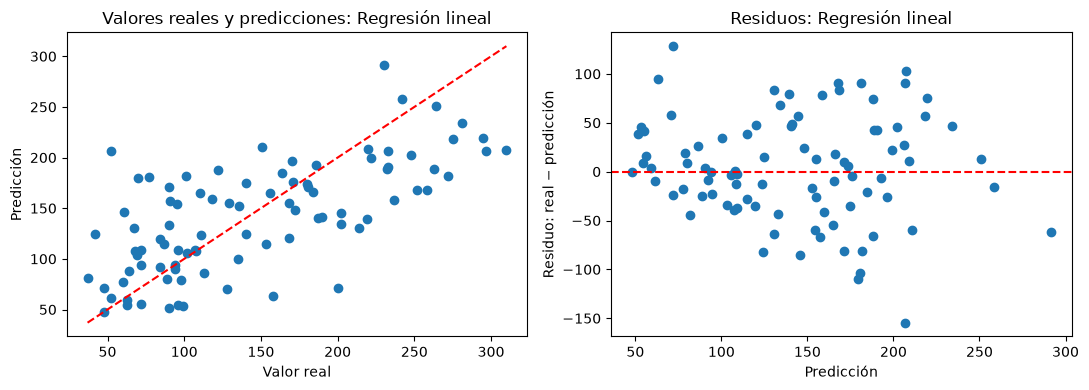

Dos errores absolutos grandes: Regresión lineal


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.03184,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,206.493375,154.493375
77,-0.096328,-0.044642,-0.036385,-0.074527,-0.03872,-0.027618,0.015505,-0.039493,-0.074093,-0.001078,200.0,71.666726,128.333274


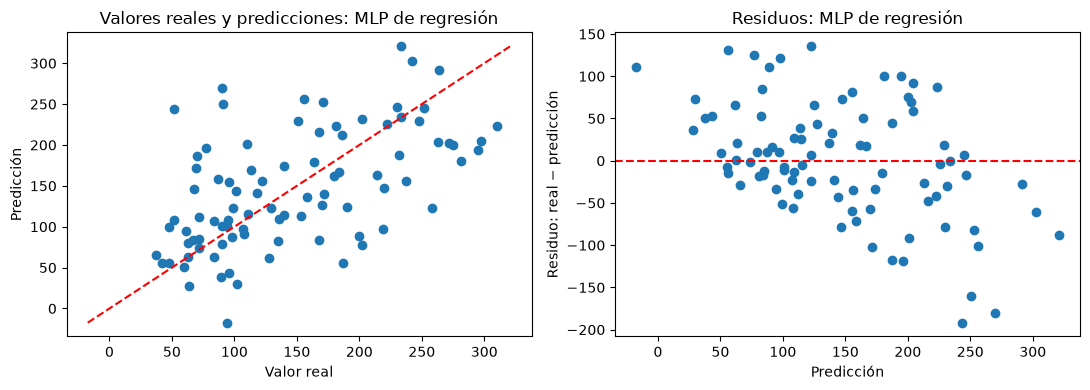

Dos errores absolutos grandes: MLP de regresión


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.031840,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,243.749141,191.749141
199,0.041708,-0.044642,-0.045007,0.034508,0.043837,-0.015719,0.037595,-0.014401,0.089897,0.007207,90.0,269.960621,179.960621


In [34]:
#Graficos 
for nombre in ["Regresión lineal", "MLP de regresión"]:
    prediccion = predicciones_prueba_diabetes[nombre]
    valores_reales = Y_test_d.to_numpy()
    residuos = valores_reales - prediccion

    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

    minimo = min(valores_reales.min(), prediccion.min())
    maximo = max(valores_reales.max(), prediccion.max())

    ejes[0].scatter(valores_reales, prediccion)
    ejes[0].plot([minimo, maximo], [minimo, maximo], "r--")
    ejes[0].set_xlabel("Valor real")
    ejes[0].set_ylabel("Predicción")
    ejes[0].set_title("Valores reales y predicciones: " + nombre)

    ejes[1].scatter(prediccion, residuos)
    ejes[1].axhline(0, color="red", linestyle="--")
    ejes[1].set_xlabel("Predicción")
    ejes[1].set_ylabel("Residuo: real − predicción")
    ejes[1].set_title("Residuos: " + nombre)

    plt.tight_layout()
    plt.show()

    prediccion_serie = pd.Series(
        prediccion,
        index=Y_test_d.index
    )

    errores_absolutos = (
        Y_test_d - prediccion_serie
    ).abs().nlargest(2)

    ejemplos_error = X_test_d.loc[
        errores_absolutos.index
    ].copy()

    ejemplos_error["Valor real"] = Y_test_d.loc[
        errores_absolutos.index
    ]

    ejemplos_error["Predicción"] = prediccion_serie.loc[
        errores_absolutos.index
    ]

    ejemplos_error["Error absoluto"] = errores_absolutos

    print("Dos errores absolutos grandes:", nombre)
    display(ejemplos_error)

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
   
Gradient Boosting de regresión	

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?

MAE calcula el promedio del tamaño de los errores. RMSE castiga más los errores grandes porque los eleva al cuadrado.

3. ¿Cómo se interpreta un R² negativo?

Un R² negativo significa que el modelo rindió peor que predecir siempre el promedio del objetivo.
4. ¿Qué efecto tuvo aumentar la regularización?

Al aumentar alpha obtuvimos mejores resultados, es decir hasta 1.0 fueron buenos, Ridge mejora entre 1 y 10 y Lasso consigue un MAE inferior alrededor de 1, o si la mejora se mantiene entre 0.5 y 3.
5. ¿Qué puede explicar los errores grandes?

Los errores grandes pueden aparecer por ruido, observaciones atípicas, variables faltantes o límites del modelo.

6. ¿Un coeficiente predictivo demuestra una relación causal?

Un coeficiente predictivo no demuestra causalidad; solamente muestra una asociación útil dentro de estos datos.